# DATA ANALYTICS ML CHALLENGE

Semana 14 PCA y evaluación de mejoras al modelo


Objetivo: examinar si reducir variables con PCA y cambiar la regularización permite identificar mejor los pedidos que llegarían después de la fecha prometida.


## 1. Carga de datos

Se integran las siete tablas del conjunto Olist. Una fila corresponde a un pedido.

In [47]:
import hashlib
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score, confusion_matrix)

In [48]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Se resumen ítems y pagos por `order_id` para conservar una fila por pedido.

In [49]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [50]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [51]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

Solo se usan datos disponibles al cierre de la compra. No se incluyen fechas de entrega real ni reseñas.

In [52]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Se conserva el ID de la semana 12. Con el mismo ID se obtiene la misma muestra de 35.000 pedidos y las mismas particiones (24.500 / 5.250 / 5.250). La partición de prueba **no** se usa para elegir modelo.

In [53]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 22
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 22 | Semilla: 1022
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 097e5bd034c8


## 3. Actividad 1. PCA y varianza explicada

Las variables numéricas se imputan (mediana) y se estandarizan; luego se calcula PCA. Todo se ajusta **solo con entrenamiento**. Se conserva el número mínimo de componentes que explica al menos el 90 % de la varianza.

Variables numéricas iniciales: 24
Componentes para explicar al menos 90 %: 15
Varianza acumulada con esas componentes: 0.9061
Varianza por componente (primeras 5): [0.1915 0.0964 0.0782 0.0737 0.0725]


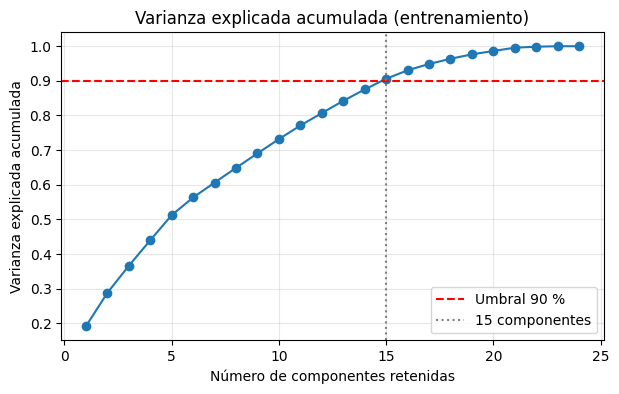

In [54]:
# Preparación numérica ajustada solo con entrenamiento.
prep_numerica = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
Z_train = prep_numerica.fit_transform(X_train[columnas_numericas])

pca_completo = PCA(svd_solver='full', random_state=semilla)
pca_completo.fit(Z_train)

varianza_acumulada = np.cumsum(pca_completo.explained_variance_ratio_)
n_variables_numericas = len(columnas_numericas)
n_componentes = int(np.searchsorted(varianza_acumulada, 0.90, side='right') + 1)

print('Variables numéricas iniciales:', n_variables_numericas)
print('Componentes para explicar al menos 90 %:', n_componentes)
print('Varianza acumulada con esas componentes:', round(float(varianza_acumulada[n_componentes - 1]), 4))
print('Varianza por componente (primeras 5):', np.round(pca_completo.explained_variance_ratio_[:5], 4))

plt.figure(figsize=(7, 4))
plt.plot(range(1, n_variables_numericas + 1), varianza_acumulada, marker='o')
plt.axhline(0.90, color='red', linestyle='--', label='Umbral 90 %')
plt.axvline(n_componentes, color='gray', linestyle=':', label=f'{n_componentes} componentes')
plt.xlabel('Número de componentes retenidas')
plt.ylabel('Varianza explicada acumulada')
plt.title('Varianza explicada acumulada (entrenamiento)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Interpretación (Actividad 1)

Se redujeron las 24 variables numéricas a 15 componentes principales, manteniendo el 90,6 % de la varianza del conjunto de entrenamiento. Dado que la primera componente solo explica cerca del 19 %, la redundancia entre las variables originales es baja, lo que limita una compresión mayor.

El *trade-off* de este proceso es la pérdida del 9,4 % de varianza y la menor interpretabilidad de los componentes. Además, al no considerar la variable objetivo, el PCA podría descartar patrones de baja varianza que resulten clave para identificar retrasos.

Finalmente, conviene recordar que la varianza conservada mide la información retenida, no la precisión final del modelo.

## 4. Actividad 2. Comparación de las cuatro configuraciones

Misma muestra, misma partición, `class_weight='balanced'` y umbral 0,50 en todos. Solo cambian PCA y el valor de C.

In [55]:
def crear_modelo(usar_pca, C):
    pasos_num = [SimpleImputer(strategy='median'), StandardScaler()]
    if usar_pca:
        pasos_num.append(PCA(n_components=0.90, svd_solver='full', random_state=semilla))
    preproc = ColumnTransformer([
        ('numericas', make_pipeline(*pasos_num), columnas_numericas),
        ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                      OneHotEncoder(handle_unknown='ignore')),
         columnas_categoricas),
    ])
    clasificador = LogisticRegression(C=C, class_weight='balanced',
                                      max_iter=1000, random_state=semilla)
    return make_pipeline(preproc, clasificador)

experimentos = {
    'A': {'descripcion': 'Referencia, sin PCA',           'usar_pca': False, 'C': 1.0},
    'B': {'descripcion': 'PCA 90 %, C=1.0',                'usar_pca': True,  'C': 1.0},
    'C': {'descripcion': 'PCA 90 %, C=0.1 (más penaliz.)', 'usar_pca': True,  'C': 0.1},
    'D': {'descripcion': 'PCA 90 %, C=10.0 (menos penaliz.)', 'usar_pca': True, 'C': 10.0},
}

modelos, predicciones, probabilidades, filas = {}, {}, {}, []
for nombre, cfg in experimentos.items():
    m = crear_modelo(cfg['usar_pca'], cfg['C'])
    m.fit(X_train, y_train)
    p = m.predict(X_valid)
    pr = m.predict_proba(X_valid)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_valid, p).ravel()
    modelos[nombre], predicciones[nombre], probabilidades[nombre] = m, p, pr
    filas.append({
        'modelo': nombre, 'descripcion': cfg['descripcion'], 'C': cfg['C'],
        'pca': cfg['usar_pca'],
        'accuracy': accuracy_score(y_valid, p),
        'precision': precision_score(y_valid, p, zero_division=0),
        'recall': recall_score(y_valid, p, zero_division=0),
        'f1': f1_score(y_valid, p, zero_division=0),
        'ap': average_precision_score(y_valid, pr),
        'FP': int(fp), 'FN': int(fn), 'TP': int(tp), 'TN': int(tn),
        'costo_brl': float(8 * fp + 35 * fn),
    })

resultados = pd.DataFrame(filas).set_index('modelo')
columnas_vista = ['descripcion', 'accuracy', 'precision', 'recall', 'f1', 'ap']
print('Componentes PCA en B:', modelos['B'].named_steps['columntransformer']
      .named_transformers_['numericas'].named_steps['pca'].n_components_)
resultados[columnas_vista].round(3)

Componentes PCA en B: 15


,descripcion,accuracy,precision,recall,f1,ap
modelo,,,,,,
A,"Referencia, sin PCA",0.665,0.125,0.654,0.210,0.162
B,"PCA 90 %, C=1.0",0.646,0.109,0.590,0.184,0.131
C,"PCA 90 %, C=0.1 (más penaliz.)",0.645,0.110,0.596,0.185,0.134
D,"PCA 90 %, C=10.0 (menos penaliz.)",0.645,0.109,0.590,0.184,0.129


### Interpretación (Actividad 2)

Se compararon cuatro configuraciones bajo idénticas condiciones de muestreo, partición y umbral (0,50). El **Modelo A** (sin PCA) obtuvo el mejor desempeño general (Recall: 0,654 / F1: 0,210 / AP: 0,162). La inclusión de PCA con $C = 1,0$ (**Modelo B**) redujo todas las métricas (Recall: 0,590 / F1: 0,184 / AP: 0,131), confirmando que reducir a 15 componentes no benefició la identificación de retrasos y probablemente descartó señales útiles al ser un proceso no supervisado. Asimismo, los modelos B, C y D mostraron métricas casi idénticas, lo que refleja un impacto insignificante de la regularización ($C$). Al tratarse de diferencias marginales en una sola partición de validación, no hay evidencia suficiente para sostener que $C = 0,1$ sea superior.

## 5. Actividad 3. Errores y costo empresarial

Supuesto didáctico del reto: R\$ 8 por falso positivo y R\$ 35 por falso negativo. Estas cifras no son costos observados de Olist.

In [56]:
costos = resultados[['FP', 'FN', 'costo_brl']].copy()
costos['costo_FP'] = 8 * costos['FP']
costos['costo_FN'] = 35 * costos['FN']
print(costos[['FP', 'FN', 'costo_FP', 'costo_FN', 'costo_brl']].to_string())

modelo_elegido = 'A'

          FP   FN  costo_FP  costo_FN  costo_brl
modelo                                          
A       1635  123     13080      4305    17385.0
B       1715  146     13720      5110    18830.0
C       1721  144     13768      5040    18808.0
D       1720  146     13760      5110    18870.0


### Justificación de la elección

Se seleccionó el **Modelo A** (sin PCA, C = 1,0) por presentar el mejor desempeño general y el menor costo (**R\$ 17.385**, frente al rango de R\$ 18.808 a R\$ 18.870 de los modelos con PCA). Con 1.635 falsos positivos y 123 falsos negativos, alcanzó también las métricas más altas: Recall (0,654), F1 (0,210) y AP (0,162). Aplicar PCA generó ~80 falsas alarmas y ~23 omisiones adicionales, lo que supuso un sobrecosto de ~R\$ 1.445.

En consecuencia, la reducción dimensional no se justifica en esta validación, pues el modelo sobre variables originales detecta más retrasos a menor costo. Cabe aclarar que las penalizaciones de R\$ 8 y R\$ 35 corresponden a un supuesto didáctico y no a costos reales de Olist. Esta decisión solo se reevaluaría si cambios en los costos o en el umbral invirtieran la ventaja del modelo, o si la compresión aportara eficiencias operativas clave sin penalizar el costo final.

## 6. Actividad 4. Prueba de Kolmogorov-Smirnov sobre `valor_flete`

**H0:** `valor_flete` tiene la misma distribución en entrenamiento y validación.  
**H1:** las distribuciones son diferentes.  
Nivel de significancia: α = 0,05.

Tamaños: train = 24500 | valid = 5250
Estadístico D: 0.0128
Valor p: 0.4725
Decisión (alfa = 0,05): No rechazar H0

       entrenamiento  validación
count       24500.00     5250.00
mean           22.66       22.78
std            23.74       20.43
min             0.00        0.00
25%            13.74       13.91
50%            17.06       17.15
75%            23.92       23.96
max          1794.96      371.46


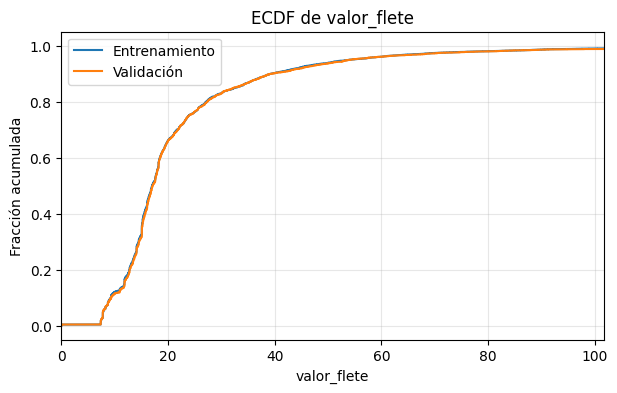

In [57]:
flete_train = train['valor_flete'].dropna()
flete_valid = valid['valor_flete'].dropna()

ks = ks_2samp(flete_train, flete_valid, alternative='two-sided')
D, p_valor = float(ks.statistic), float(ks.pvalue)
decision = 'Rechazar H0' if p_valor < 0.05 else 'No rechazar H0'

print('Tamaños: train =', len(flete_train), '| valid =', len(flete_valid))
print('Estadístico D:', round(D, 4))
print('Valor p:', round(p_valor, 4))
print('Decisión (alfa = 0,05):', decision)
print()
print(pd.DataFrame({'entrenamiento': flete_train.describe(), 'validación': flete_valid.describe()}).round(2))

# ECDF para visualizar D.
plt.figure(figsize=(7, 4))
for datos, etiqueta in [(flete_train, 'Entrenamiento'), (flete_valid, 'Validación')]:
    x = np.sort(datos.values)
    plt.step(x, np.arange(1, len(x) + 1) / len(x), where='post', label=etiqueta)
plt.xlim(0, flete_train.quantile(0.99))
plt.xlabel('valor_flete')
plt.ylabel('Fracción acumulada')
plt.title('ECDF de valor_flete')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Interpretación (Actividad 4)

**H0:** `valor_flete` tiene la misma distribución en entrenamiento y validación.  
**H1:** Las distribuciones son diferentes.

La prueba Kolmogorov-Smirnov (KS) bilateral dio un estadístico D = 0,0128 y un p-valor = 0,4725 (con n = 24.500 y 5.250). Como el p-valor es mayor que el nivel de significancia α = 0,05, **no se rechaza H0**: no hay evidencia estadística suficiente de que la distribución del flete difiera entre ambas particiones.

Esto concuerda con las curvas ECDF (que casi se superponen) y con las métricas descriptivas:
* **Medias:** 22,66 (entrenamiento) frente a 22,78 (validación)
* **Medianas:** 17,06 (entrenamiento) frente a 17,15 (validación)

La desviación estándar sí presenta una diferencia (23,74 frente a 20,43), explicada por un valor extremo en el conjunto de entrenamiento que la prueba KS casi no detecta.

**Limitaciones a considerar:**
1. No rechazar H0 no demuestra formalmente que las distribuciones sean idénticas.
2. La prueba analiza únicamente `valor_flete`, por lo que no arroja información sobre el resto de las variables ni sobre el rendimiento futuro de los modelos.
3. Debido a la presencia de valores repetidos en `valor_flete`, el p-valor calculado debe tomarse como una aproximación.

### Autoverificación

Ejecute estas comprobaciones después de completar las actividades.

In [58]:
assert len(muestra) == 35000, 'La muestra debe tener 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250), 'Particiones esperadas: 24500 / 5250 / 5250.'
assert set(train['order_id']).isdisjoint(valid['order_id']), 'Train y valid comparten pedidos.'
assert set(train['order_id']).isdisjoint(test['order_id']), 'Train y test comparten pedidos.'
assert set(valid['order_id']).isdisjoint(test['order_id']), 'Valid y test comparten pedidos.'

assert 1 <= n_componentes <= n_variables_numericas, 'Revise el número de componentes.'
assert varianza_acumulada[n_componentes - 1] >= 0.90, 'Las componentes retenidas deben explicar al menos 90 %.'
n_pca_B = (modelos['B'].named_steps['columntransformer']
           .named_transformers_['numericas'].named_steps['pca'].n_components_)
assert n_pca_B == n_componentes, 'El PCA del modelo B no coincide con la curva de varianza.'

assert set(resultados.index) == {'A', 'B', 'C', 'D'}, 'Faltan experimentos.'
for k in 'ABCD':
    assert len(predicciones[k]) == len(y_valid), f'Predicciones de {k} incompletas.'
    tn_, fp_, fn_, tp_ = confusion_matrix(y_valid, predicciones[k]).ravel()
    assert np.isclose(resultados.loc[k, 'costo_brl'], 8 * fp_ + 35 * fn_), f'Costo de {k} no coincide.'

assert modelo_elegido in ('A', 'B', 'C', 'D'), "Escriba en modelo_elegido 'A', 'B', 'C' o 'D'."
assert 0 <= D <= 1 and 0 <= p_valor <= 1, 'Revise la prueba KS.'
print('Autoverificación superada.')

Autoverificación superada.


## 7. Registro de resultados

Se guardan el registro de experimentos (CSV) y el resumen (JSON) en `reports/`.

In [60]:
reporte = {
    'laboratorio': 'S14',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'n_muestra': len(muestra), 'n_train': len(train),
    'n_valid': len(valid), 'n_test': len(test),
    'huella_muestra': huella_muestra,
    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf',
    'umbral_clasificacion': 0.50,
    'class_weight': 'balanced',
    'pca': {'variables_numericas': n_variables_numericas,
            'componentes_90pct': n_componentes,
            'varianza_acumulada': float(varianza_acumulada[n_componentes - 1])},
    'experimentos': json.loads(resultados.reset_index().to_json(orient='records')),
    'modelo_elegido': modelo_elegido,
    'ks_valor_flete': {'D': D, 'p_valor': p_valor, 'alfa': 0.05,
                       'n_train': int(len(flete_train)), 'n_valid': int(len(flete_valid)),
                       'decision': decision},
}

Path('reports').mkdir(parents=True, exist_ok=True)
ruta_json = Path(f'reports/S14_resultados_ID_{identificador}.json')
ruta_csv = Path(f'reports/S14_experimentos_ID_{identificador}.csv')
ruta_json.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')
resultados.reset_index().to_csv(ruta_csv, index=False)
print('Guardados:', ruta_json, 'y', ruta_csv)

try:
    from google.colab import files
    files.download(str(ruta_json))
    files.download(str(ruta_csv))
except Exception:
    print('Si no se descargaron automáticamente, guárdelos manualmente desde reports/.')

Guardados: reports/S14_resultados_ID_22.json y reports/S14_experimentos_ID_22.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>